# 04 · A live twin: the Kalman filter
**Level: Intermediate** · ~20 min · *Track: Data assimilation*

Calibration (03) fits parameters once. A real twin runs **online**: every time a sensor reading
arrives it corrects its state, so it never drifts far from reality. The canonical tool is the
**Kalman filter (KF)**, which alternates two steps:

| Step | Equation | Meaning |
|---|---|---|
| **Forecast** | $x^f_{k} = M x^a_{k-1}$, $\;P^f_k = M P^a_{k-1} M^\top + Q$ | run the physics; uncertainty grows by model error $Q$ |
| **Analysis** | $K = P^f H^\top (H P^f H^\top + R)^{-1}$ | weigh model vs. sensors |
| | $x^a_k = x^f_k + K(y_k - H x^f_k)$, $\;P^a_k=(I-KH)P^f_k$ | correct the state; uncertainty shrinks |

The KF is *optimal* for linear models with Gaussian noise, and the heat equation is linear. The
covariance $P$ also spreads information from the sensors to **unobserved** points.

**The scenario:** the rod's heater power $q(t)$ is unknown and changes over time (an operator
turns a knob). We estimate the full temperature field **and** $q(t)$ live from 5 thermometers,
none of which sits on the heater. That trick is called **state augmentation**.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import chi2
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import Heat1D
from dtwin.sensors import PointSensors, evenly_spaced_1d
from dtwin.assimilation import KalmanFilter
viz.set_style()
rng = np.random.default_rng(7)

## 1. Reality: an operator-controlled heater plus small unmodelled disturbances

In [2]:
NX, DT, NSTEP, ALPHA = 81, 0.05, 400, 0.012
rod = Heat1D(nx=NX, alpha=ALPHA, dt=DT)
x = rod.x
b = np.exp(-((x - 0.35) / 0.05) ** 2)        # heater footprint (known)

def q_true(t):                               # heater power (unknown to the twin)
    return np.select([t < 4, t < 9, t < 14], [0.5, 1.2, 1.2 - 0.12 * (t - 9)], 0.3)

t = np.arange(NSTEP + 1) * DT
U_true = np.zeros((NSTEP + 1, NX))
for k in range(NSTEP):
    disturbance = gaussian_filter1d(rng.standard_normal(NX), 3) * 0.004 * rod.mask
    U_true[k + 1] = rod.step(U_true[k], q_true(t[k]) * b) + disturbance

sens = PointSensors(evenly_spaced_1d(NX, 5), NX, noise_std=0.01)
Y = sens.observe(U_true, rng)
xs = x[sens.idx]

## 2. Building the filter: augmented linear model
Write the state as $z = [u;\, q]$. The heater power has no dynamics of its own, so we model it as
a **random walk** $q_{k+1} = q_k + \eta_k$: "it stays the same unless the data say otherwise."

$$\begin{bmatrix}u\\q\end{bmatrix}_{k+1} = \underbrace{\begin{bmatrix}M & G b\\ 0 & 1\end{bmatrix}}_{M_{\text{aug}}}\begin{bmatrix}u\\q\end{bmatrix}_k + w_k,\qquad Q = \operatorname{diag}(\sigma_u^2 I,\ \sigma_q^2)$$

The size of $\sigma_q$ encodes how fast we believe the knob can move. It is the main tuning knob.

In [3]:
M, G = rod.transition_matrices()
n = NX + 1
M_aug = np.zeros((n, n))
M_aug[:NX, :NX] = M
M_aug[:NX, NX] = G @ b
M_aug[NX, NX] = 1.0
H_aug = np.hstack([sens.H, np.zeros((sens.m, 1))])

def run_kf(sigma_q=0.03, sigma_u=0.004, q0=0.3):
    Q = np.diag(np.r_[np.full(NX, sigma_u**2) * rod.mask + 1e-12, sigma_q**2])
    kf = KalmanFilter(M_aug, H_aug, Q, sens.R)
    z = np.r_[np.zeros(NX), q0]
    P = np.diag(np.r_[np.full(NX, 1e-4), 0.5**2])
    Z, S_diag, nis = [z], [np.sqrt(np.diag(P))], [np.nan]
    for k in range(1, NSTEP + 1):
        z, P = kf.predict(z, P)
        z, P, innov, S = kf.update(z, P, Y[k])
        Z.append(z)
        S_diag.append(np.sqrt(np.diag(P)))
        nis.append(innov @ np.linalg.solve(S, innov))
    return np.array(Z), np.array(S_diag), np.array(nis), P

Z, SD, NIS, P_final = run_kf()
U_kf, q_kf, U_sd, q_sd = Z[:, :NX], Z[:, NX], SD[:, :NX], SD[:, NX]

# open-loop twin for comparison: assumes a constant heater power of 0.6
U_open = np.zeros_like(U_true)
for k in range(NSTEP):
    U_open[k + 1] = rod.step(U_open[k], 0.6 * b)

## 3. The twin sees the whole field

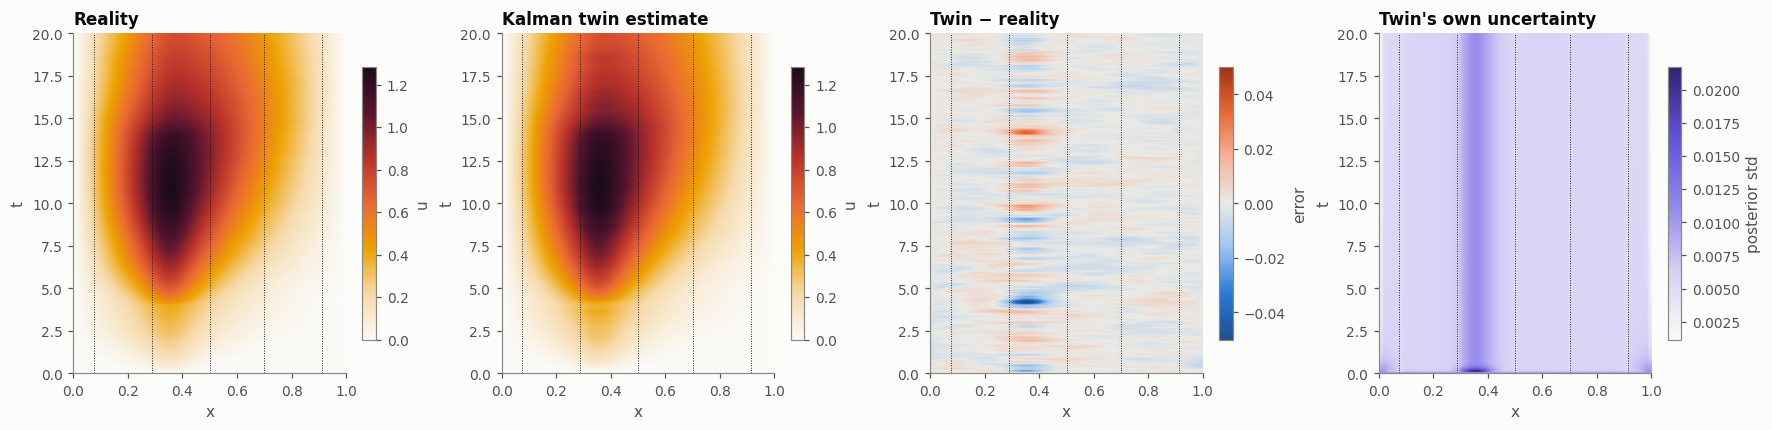

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
vmax = U_true.max()
viz.spacetime(axes[0], U_true, x, t, vmin=0, vmax=vmax, label="u")
axes[0].set_title("Reality")
viz.spacetime(axes[1], U_kf, x, t, vmin=0, vmax=vmax, label="u")
axes[1].set_title("Kalman twin estimate")
err = U_kf - U_true
viz.spacetime(axes[2], err, x, t, cmap=viz.DIVERGING, vmin=-0.05, vmax=0.05, label="error")
axes[2].set_title("Twin − reality")
viz.spacetime(axes[3], U_sd, x, t, cmap=viz.UNCERTAINTY, label="posterior std")
axes[3].set_title("Twin's own uncertainty")
for ax in axes:
    for xi in xs:
        ax.axvline(xi, color=viz.INK, lw=0.6, ls=":")
viz.save(fig, "04_kalman_field.png")
plt.show()

Note the stripes in the uncertainty map: the std collapses at the sensors (dotted lines) and
stays largest midway between them and around the heater. **A good twin knows where it is unsure.**

## 4. Estimating something no sensor measures: the heater power

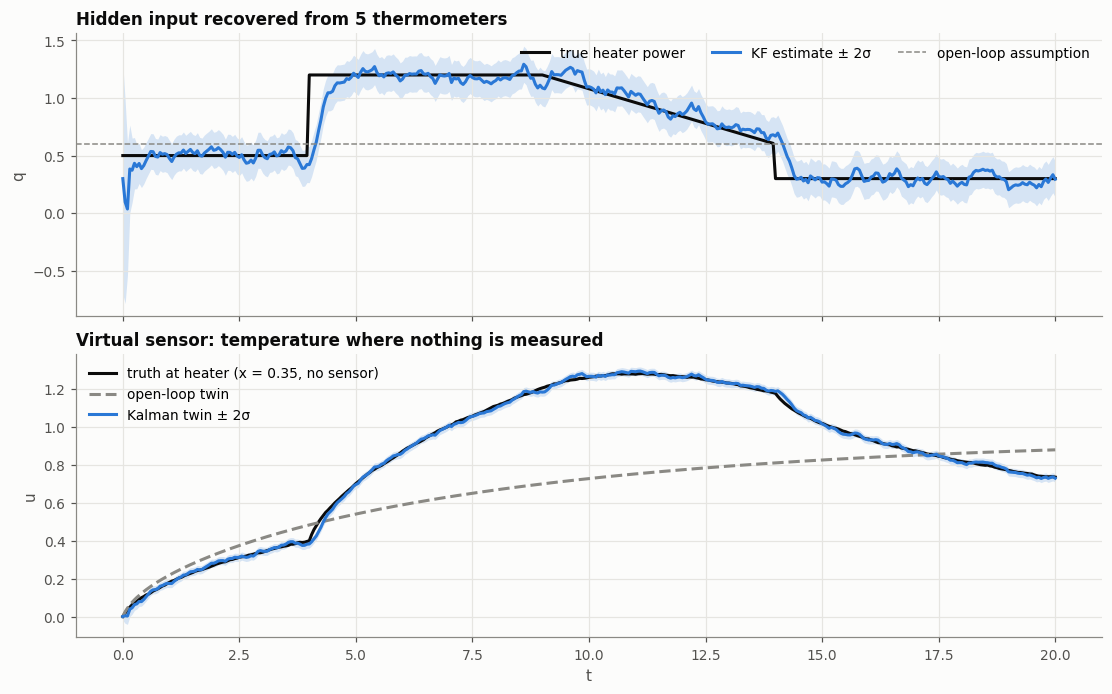

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), constrained_layout=True, sharex=True)
ax = axes[0]
ax.plot(t, q_true(t), color=viz.TRUTH, lw=2, label="true heater power")
viz.band(ax, t, q_kf, q_sd, color=viz.TWIN, label="KF estimate ± 2σ")
ax.axhline(0.6, color=viz.MUTED, ls="--", lw=1, label="open-loop assumption")
ax.set(ylabel="q", title="Hidden input recovered from 5 thermometers")
ax.legend(ncol=3, loc="upper right")

ax = axes[1]
ih = np.argmin(abs(x - 0.35))
ax.plot(t, U_true[:, ih], color=viz.TRUTH, lw=2, label="truth at heater (x = 0.35, no sensor)")
ax.plot(t, U_open[:, ih], color=viz.MUTED, ls="--", label="open-loop twin")
viz.band(ax, t, U_kf[:, ih], U_sd[:, ih], color=viz.TWIN, label="Kalman twin ± 2σ")
ax.set(xlabel="t", ylabel="u", title="Virtual sensor: temperature where nothing is measured")
ax.legend(loc="upper left")
plt.show()

The estimate lags the true power by a fraction of a time unit: heat needs time to diffuse to the
sensors, so no filter can react instantly. This lag is a physical limit, not a bug.

## 5. Accuracy over time

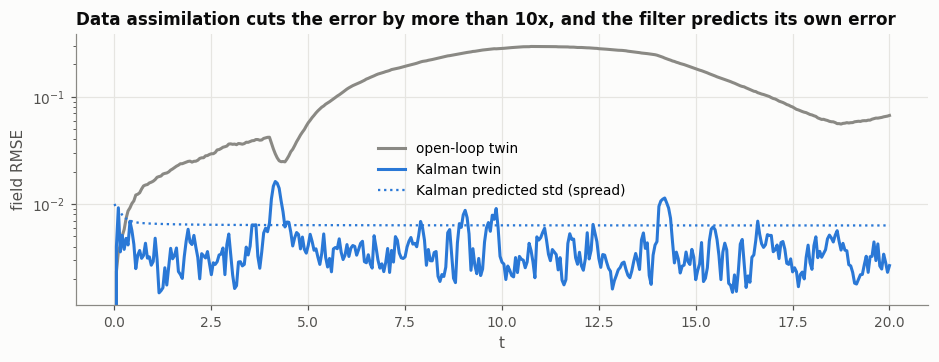

In [6]:
rmse = lambda A: np.sqrt(((A - U_true) ** 2).mean(1))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, rmse(U_open), color=viz.MUTED, label="open-loop twin")
ax.plot(t, rmse(U_kf), color=viz.TWIN, label="Kalman twin")
ax.plot(t, np.sqrt((U_sd**2).mean(1)), color=viz.TWIN, ls=":", lw=1.5, label="Kalman predicted std (spread)")
ax.set(xlabel="t", ylabel="field RMSE", yscale="log", title="Data assimilation cuts the error by more than 10x, and the filter predicts its own error")
ax.legend()
plt.show()

## 6. What the covariance knows
The final $P$ matrix as a correlation map. Rows/columns 0-80 are rod positions, the last one is the
heater power. Bright off-diagonal bands mean "learning about one point tells you about the
other". The heater row shows *where on the rod* temperature errors are correlated with errors in $q$.

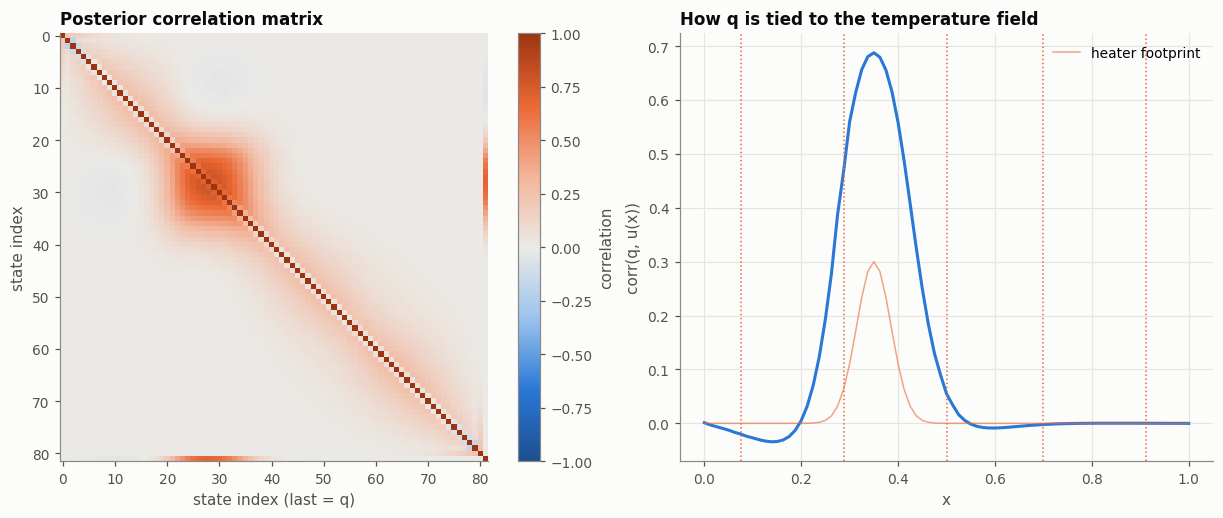

In [7]:
sd = np.sqrt(np.diag(P_final))
Corr = P_final / np.outer(sd, sd)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].grid(False)
im = axes[0].imshow(Corr, cmap=viz.DIVERGING, vmin=-1, vmax=1, interpolation="nearest")
plt.colorbar(im, ax=axes[0], label="correlation")
axes[0].set(title="Posterior correlation matrix", xlabel="state index (last = q)", ylabel="state index")
axes[1].plot(x, Corr[NX, :NX], color=viz.TWIN)
for xi in xs:
    axes[1].axvline(xi, color=viz.DATA, lw=1, ls=":")
axes[1].plot(x, 0.3 * b, color=viz.ORANGE, lw=1, alpha=0.6, label="heater footprint")
axes[1].set(xlabel="x", ylabel="corr(q, u(x))", title="How q is tied to the temperature field")
axes[1].legend()
plt.show()

## 7. Is the filter honest? Consistency check
If the model and noise assumptions are right, the **normalised innovation squared**
$\mathrm{NIS}_k = d_k^\top S_k^{-1} d_k$ follows a $\chi^2_m$ distribution ($m=5$ sensors). Too
high means the filter is over-confident (Q too small); too low means it's too timid. This is also
the basis of **anomaly detection** in the capstone (notebook 10).

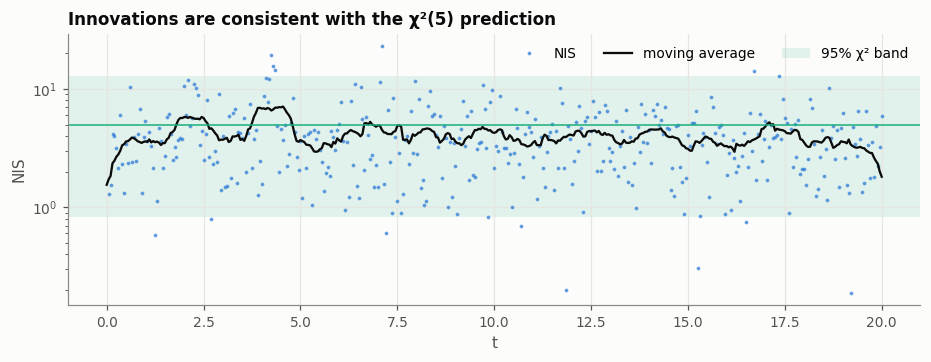

In [8]:
lo, hi = chi2.ppf([0.025, 0.975], sens.m)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, NIS, ".", color=viz.TWIN, ms=3, alpha=0.6, label="NIS")
ax.plot(t, np.convolve(np.nan_to_num(NIS, nan=sens.m), np.ones(20) / 20, mode="same"), color=viz.INK, lw=1.5, label="moving average")
ax.axhspan(lo, hi, color=viz.AQUA, alpha=0.12, lw=0, label="95% χ² band")
ax.axhline(sens.m, color=viz.AQUA, lw=1)
ax.set(xlabel="t", ylabel="NIS", yscale="log", title="Innovations are consistent with the χ²(5) prediction")
ax.legend(ncol=3)
plt.show()

## 8. Tuning: the process noise trade-off
$\sigma_q$ says how fast the twin *believes* the heater can change.

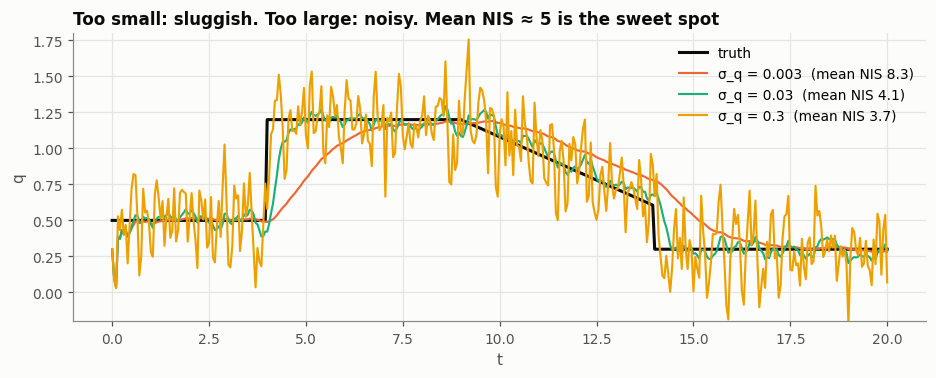

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t, q_true(t), color=viz.TRUTH, lw=2, label="truth")
for i, sq in enumerate([0.003, 0.03, 0.3]):
    Zs, _, nis_s, _ = run_kf(sigma_q=sq)
    ax.plot(t, Zs[:, NX], color=viz.SERIES[i + 1], lw=1.4,
            label=f"σ_q = {sq}  (mean NIS {np.nanmean(nis_s):.1f})")
ax.set(xlabel="t", ylabel="q", ylim=(-0.2, 1.8), title="Too small: sluggish. Too large: noisy. Mean NIS ≈ 5 is the sweet spot")
ax.legend(loc="upper right")
plt.show()

## 9. Watch the twin track reality

In [10]:
idx = np.arange(0, NSTEP + 1, 6)
fig_anim = viz.animate_1d(x, [U_true[idx], U_kf[idx], U_open[idx]], t[idx],
                          labels=["reality", "Kalman twin", "open-loop twin"],
                          colors=[viz.TRUTH, viz.TWIN, viz.MUTED], styles=["-", "-", "--"],
                          points=(xs, Y[idx]), title="Live twin")
HTML(fig_anim.to_jshtml())

## Recap
* The Kalman filter = physics forecast + statistically optimal correction.
* **State augmentation** turns unknown inputs/parameters into states, so the twin estimates them live.
* $P$ quantifies uncertainty everywhere, including at unsensed points (virtual sensors).
* NIS checks whether the filter is statistically consistent; it also powers anomaly alarms.

**Limits:** the KF needs the full $n\times n$ covariance ($O(n^2)$ memory, $O(n^3)$ time) and a
linear model. In 2D with thousands of cells and nonlinear parameter dependence we need the
**ensemble Kalman filter** (06).

**Exercises**
1. Remove 3 sensors. Where does uncertainty grow most?
2. Make $\alpha$ wrong by 30% in the twin. What does NIS do? Can you also augment $\alpha$? (Hint: it enters $M$ nonlinearly, so try the EnKF.)